# Import the libraries


1.   numpy
2.   pandas
3.   pyplot from matplotlib
4.   seaborn





In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

# Set random seed for complete reproducibility across runs
np.random.seed(1)

NumPy version: 2.5.3
Pandas version: 2.3.3


In [71]:
# Evaluation cell, Skip it ...

# Exercise 1 (03 points)

The spam table of §4.2 is S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]]) (links, words in
subject), weights Θ = (0.3, 0.7), bias 0.5.
1. Compute z = S @ np.array([0.3, 0.7]) + 0.5 and check that the first value is 6.3 as in the lecture.
2. Apply the sigmoid 1 / (1 + np.exp(-z)) to the whole vector. Which e-mails are predicted as spam
(probability ≥ 0.5)?

In [72]:
S = np.array([[10, 4], [2, 1], [7, 3], [1, 2]])
theta = np.array([0.3, 0.7])
bias = 0.5

# 1. Linear combination z
z = S @ theta + bias
print(z)  # first value is 6.3

# 2. Sigmoid probabilities and spam prediction
probabilities= 1 / (1 + np.exp(-z))
print(probabilities.round(4))

predicted_spam =probabilities >= 0.5
print(predicted_spam)

[6.3 1.8 4.7 2.2]
[0.9982 0.8581 0.991  0.9002]
[ True  True  True  True]


In [73]:
# Auto-graded cell (S)
# Skip it

In [74]:
# Auto-graded cell (theta)
# Skip it

In [75]:
# Auto-graded cell (bias)
# Skip it

In [76]:
# Auto-graded cell (z)
# Skip it

In [77]:
# Auto-graded cell (probabilities) 
# Skip it

In [78]:
# Auto-graded cell predicted_spam
# Skip it

# Exercise 2 (05 points)
Let's create a log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.

In [79]:
# Create the log of 300 login events with a few missing values and a few suspicious bursts of failed attempts.
rng = np.random.default_rng(1)
n = 300
log = pd.DataFrame({"user":    rng.choice(["ali", "sara", "yacine", "nour", "karim"], n),
                    "hour":    rng.integers(0, 24, n),
                    "failed_attempts": rng.poisson(0.4, n),
                    "country": rng.choice(["DZ", "FR", "TN", "RU"], n, p=[.7, .15, .1, .05]),
                    "duration_min": rng.gamma(2, 8, n).round(1)})

In [80]:
# Auto graded cell (log)
# skip it

In [81]:
# Choose randomly 12 different indexes and set 12 integer values from [5,11[ in the feature "failed_attempt"

indexes = random.sample(log.index.tolist(), 12)  # 12 distinct indexes
values = [random.randrange(5, 11) for _ in range(12)]
log.loc[indexes, "failed_attempt"] = values


In [82]:
# Autograded cell (Failed attempts)
# Skip it

In [83]:
# Insert 10 missing values randomly

missing_idx = random.sample(df.index.tolist(), 10)
df.loc[missing_idx, "failed_attempt"] = np.nan

In [84]:
# Auto graded cell (missing values)
# skip it

1. How many logins come from Russia (RU) with at least 5 failed attempts?

In [85]:

ru_log_at_least_five_attempts = log[log["failed_attempts"] >= 5 ]

In [86]:
# Auto-graded cell (ru_log_at_least_five_attempts)
# Skip it

2. Which user has the highest total number of failed attempts? (groupby + sum + sort_values)

In [87]:

 user_max_failed_attempts =  (log.groupby("user")["failed_attempt"]
                            .sum()
                            .sort_values(ascending=False)
                            )


In [88]:
# Auto-graded cell user_max_failed_attemps)
# Skip it

3. Add a column long_session equal to 1 when duration_min is above 30.

In [89]:

log["long_session"] = (log["duration_min"] > 30).astype(int)

In [90]:
# Autograded cell - Skip it

# Exercise 3 (03 points)
1. Draw the histogram of failed_attempts.
2. Why is a histogram better than the mean (0.7) to describe this column?
3. Then draw a bar chart of the mean failed_attempts per night value.

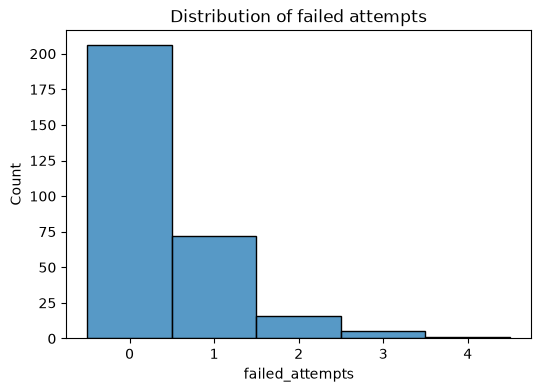

In [91]:
# Draw the histogram of failed_attempts.
plt.figure(figsize=(6, 4))
sns.histplot(log["failed_attempts"], bins=range(0, 12), discrete=True)
plt.xlabel("failed_attempts"); plt.title("Distribution of failed attempts")
plt.show()

In [92]:
# Auto-graded cell - Skip it...

In [93]:
2. Why is a histogram better than the mean (0.7) to describe this column?
    A: The mean is too difficult to calculate.
    B: The distribution is highly skewed with zero-inflation and rare extreme bursts.
    C: Histograms only work with categorical data.
    D: The mean cannot be calculated for numeric values.

IndentationError: unexpected indent (1357432129.py, line 2)

In [ ]:
# Write your code here
answer_q2 = A

In [ ]:
# 3. Draw a bar chart of the mean failed_attempts per night value.

log["night"] = ((log["hour"] >= 22) | (log["hour"] < 6)).astype(int)

log.groupby("night")["failed_attempts"].mean().plot(kind="bar", rot=0)
plt.ylabel("mean failed_attempts"); plt.title("Mean failed attempts: day (0) vs night (1)")
plt.show()

In [ ]:
# Auttograded cell - Skip it

Q1. If (300, 4) is the shape of a numpy array X.
What does X[:, 2] return? (01 point)

In [ ]:
**Q1.** `X[:, 2]` returns all 300 rows of the third column (index 2) of X, as a 1-D array of 

Q2. Give the Pandas command that shows the number of missing values in each column of a given df. (01 point)

In [ ]:
log.isna().sum()   # or log.isnull().sum()

Q3. Which plot would you use to see whether logins from RU have more failed attempts than logins from DZ? (01 point)

In [ ]:
sns.boxplot(data=log[log["country"].isin(["RU", "DZ"])], x="country", y="failed_attempts")
plt.show()

Q4. Why do we scale features before training a model (one sentence)? (01 point)

In [ ]:
We scale features so that those with large ranges (e.g. duration_min) don't dominate those with small ranges, and so gradient-based training converges faster.

Commit the logins_clean.csv.(0.5 point)

In [ ]:
# save the cleaned table in login_clean.csv
log_clean = log.copy()
log_clean["duration_min"] = log_clean["duration_min"].fillna(log_clean["duration_min"].median())
log_clean.to_csv("logins_clean.csv", index=False)

In [ ]:
# Autograded cell - Skip it

# Bonus (02 points)
On logins_clean.csv, build the matrix X with the columns hour, failed_attempts,
duration_min, night using df[cols].to_numpy(), scale it as in Cell 1.5, and print its shape. This is exactly the input Workshop 2 will feed to Scikit-learn.

In [ ]:
df = pd.read_csv("logins_clean.csv")
cols = ["hour", "failed_attempts", "duration_min", "night"]

X = df[cols].to_numpy(dtype=float)
X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)   # standardization (z-score)

print(X_scaled.shape)

In [ ]:
import numpy as np
import pandas as pd
